In [58]:
%matplotlib inline
import pandas as pd
import requests
from io import StringIO
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
url = 'https://uk.wikipedia.org/wiki/%D0%9D%D0%B0%D1%81%D0%B5%D0%BB%D0%B5%D0%BD%D0%BD%D1%8F_%D0%A3%D0%BA%D1%80%D0%B0%D1%97%D0%BD%D0%B8#%D0%9D%D0%B0%D1%80%D0%BE%D0%B4%D0%B6%D1%83%D0%B2%D0%B0%D0%BD%D1%96%D1%81%D1%82%D1%8C%22%27'

headers = {
"User-Agent": "Mozilla/5.0",
"Accept-Language": "uk-UA,uk;q=0.9,en;q=0.8",
}

html = requests.get(url, headers=headers, timeout=30).text

df = pd.read_html(
StringIO(html),
match="Коефіцієнт народжуваності в регіонах України",
thousands=".", decimal=","
)[0]

#Вивести перші рядки таблиці за допомогою методу head

In [59]:
print(df.head())

             Регіон  1950  1960  1970  1990  2000  2012  2014  2019
0              Крим  23.0  20.6  16.0  13.0   7.3  12.6     —     —
1         Вінницька  22.4  19.2  14.2  12.4   8.4  11.2  10.9   7.6
2         Волинська  24.7  25.0  17.9  15.3  11.2  14.8  14.1  10.1
3  Дніпропетровська  20.4  20.4  15.1  12.3   7.1  11.2  11.1   7.1
4          Донецька  27.1  21.4  14.0  10.9   6.1   9.8   8.2     —


Визначте кількість рядків та стовпців у датафреймі (атрибут shape)

In [60]:
print(df.shape)

(28, 9)


Замініть у таблиці значення "—" на значення NaN

In [61]:
df=df.replace("—", np.nan)
print(df)

               Регіон  1950  1960  1970  1990  2000  2012  2014  2019
0                Крим  23.0  20.6  16.0  13.0   7.3  12.6   NaN   NaN
1           Вінницька  22.4  19.2  14.2  12.4   8.4  11.2  10.9   7.6
2           Волинська  24.7  25.0  17.9  15.3  11.2  14.8  14.1  10.1
3    Дніпропетровська  20.4  20.4  15.1  12.3   7.1  11.2  11.1   7.1
4            Донецька  27.1  21.4  14.0  10.9   6.1   9.8   8.2   NaN
5         Житомирська  26.1  22.3  15.9  12.9   8.9  12.2  12.0   7.9
6        Закарпатська  31.4  27.3  20.7  16.8  11.5  15.1  14.6  10.4
7          Запорізька  21.9  19.7  15.0  12.4   7.1  10.6  10.6   6.8
8   Івано-Франківська  24.3  24.8  18.2  15.5  10.3  12.4  12.2   8.8
9            Київська  20.4  18.9  15.6  12.3   7.3  12.2  12.1   8.0
10     Кіровоградська  21.6  17.1  14.5  12.6   7.9  11.0  10.8   6.8
11          Луганська  26.2  23.5  14.4  11.6   6.2   9.6   5.1   NaN
12          Львівська  23.4  24.0  17.1  14.0   9.1  11.9  11.9   8.7
13       Миколаївськ

Визначте типи всіх стовпців за допомогою dataframe.dtypes

In [62]:
print(df.dtypes)

Регіон        str
1950      float64
1960      float64
1970      float64
1990      float64
2000      float64
2012      float64
2014          str
2019          str
dtype: object


Замініть типи нечислових колонок на числові. Підказка - це колонки, де знаходився символ "—"

In [63]:
cols = df.columns[1:]
df[cols] = df[cols].apply(pd.to_numeric, errors="coerce")
print(df)
print(df.dtypes)

               Регіон  1950  1960  1970  1990  2000  2012  2014  2019
0                Крим  23.0  20.6  16.0  13.0   7.3  12.6   NaN   NaN
1           Вінницька  22.4  19.2  14.2  12.4   8.4  11.2  10.9   7.6
2           Волинська  24.7  25.0  17.9  15.3  11.2  14.8  14.1  10.1
3    Дніпропетровська  20.4  20.4  15.1  12.3   7.1  11.2  11.1   7.1
4            Донецька  27.1  21.4  14.0  10.9   6.1   9.8   8.2   NaN
5         Житомирська  26.1  22.3  15.9  12.9   8.9  12.2  12.0   7.9
6        Закарпатська  31.4  27.3  20.7  16.8  11.5  15.1  14.6  10.4
7          Запорізька  21.9  19.7  15.0  12.4   7.1  10.6  10.6   6.8
8   Івано-Франківська  24.3  24.8  18.2  15.5  10.3  12.4  12.2   8.8
9            Київська  20.4  18.9  15.6  12.3   7.3  12.2  12.1   8.0
10     Кіровоградська  21.6  17.1  14.5  12.6   7.9  11.0  10.8   6.8
11          Луганська  26.2  23.5  14.4  11.6   6.2   9.6   5.1   NaN
12          Львівська  23.4  24.0  17.1  14.0   9.1  11.9  11.9   8.7
13       Миколаївськ

Порахуйте, яка частка пропусків міститься в кожній колонці

In [64]:
print(df.isnull().sum() / len(df) * 100)

Регіон     0.000000
1950       7.142857
1960       3.571429
1970       3.571429
1990       0.000000
2000       0.000000
2012       0.000000
2014       7.142857
2019      14.285714
dtype: float64


Видаліть з таблиці дані по всій країні, останній рядок таблиці

In [65]:
df=df.drop(df.index[-1])
print(df)


               Регіон  1950  1960  1970  1990  2000  2012  2014  2019
0                Крим  23.0  20.6  16.0  13.0   7.3  12.6   NaN   NaN
1           Вінницька  22.4  19.2  14.2  12.4   8.4  11.2  10.9   7.6
2           Волинська  24.7  25.0  17.9  15.3  11.2  14.8  14.1  10.1
3    Дніпропетровська  20.4  20.4  15.1  12.3   7.1  11.2  11.1   7.1
4            Донецька  27.1  21.4  14.0  10.9   6.1   9.8   8.2   NaN
5         Житомирська  26.1  22.3  15.9  12.9   8.9  12.2  12.0   7.9
6        Закарпатська  31.4  27.3  20.7  16.8  11.5  15.1  14.6  10.4
7          Запорізька  21.9  19.7  15.0  12.4   7.1  10.6  10.6   6.8
8   Івано-Франківська  24.3  24.8  18.2  15.5  10.3  12.4  12.2   8.8
9            Київська  20.4  18.9  15.6  12.3   7.3  12.2  12.1   8.0
10     Кіровоградська  21.6  17.1  14.5  12.6   7.9  11.0  10.8   6.8
11          Луганська  26.2  23.5  14.4  11.6   6.2   9.6   5.1   NaN
12          Львівська  23.4  24.0  17.1  14.0   9.1  11.9  11.9   8.7
13       Миколаївськ

Замініть відсутні дані в стовпцях середніми значеннями цих стовпців

In [66]:
df[cols] = df[cols].fillna(df[cols].mean())
print(df.round(1))

               Регіон  1950  1960  1970  1990  2000  2012  2014  2019
0                Крим  23.0  20.6  16.0  13.0   7.3  12.6  11.1   8.0
1           Вінницька  22.4  19.2  14.2  12.4   8.4  11.2  10.9   7.6
2           Волинська  24.7  25.0  17.9  15.3  11.2  14.8  14.1  10.1
3    Дніпропетровська  20.4  20.4  15.1  12.3   7.1  11.2  11.1   7.1
4            Донецька  27.1  21.4  14.0  10.9   6.1   9.8   8.2   8.0
5         Житомирська  26.1  22.3  15.9  12.9   8.9  12.2  12.0   7.9
6        Закарпатська  31.4  27.3  20.7  16.8  11.5  15.1  14.6  10.4
7          Запорізька  21.9  19.7  15.0  12.4   7.1  10.6  10.6   6.8
8   Івано-Франківська  24.3  24.8  18.2  15.5  10.3  12.4  12.2   8.8
9            Київська  20.4  18.9  15.6  12.3   7.3  12.2  12.1   8.0
10     Кіровоградська  21.6  17.1  14.5  12.6   7.9  11.0  10.8   6.8
11          Луганська  26.2  23.5  14.4  11.6   6.2   9.6   5.1   8.0
12          Львівська  23.4  24.0  17.1  14.0   9.1  11.9  11.9   8.7
13       Миколаївськ

Отримайте список регіонів, де рівень народжуваності у 2019 році був вищим за середній по Україні

In [67]:
average=df["2019"].sum() / len(df)
print(df["Регіон"][df["2019"]>average])

2             Волинська
6          Закарпатська
8     Івано-Франківська
12            Львівська
14              Одеська
16           Рівненська
20           Херсонська
23          Чернівецька
25                 Київ
Name: Регіон, dtype: str


У якому регіоні була найвища народжуваність у 2014 році?

In [68]:
print(df["Регіон"][df["2014"]==df["2014"].max()])

16    Рівненська
Name: Регіон, dtype: str


Побудуйте стовпчикову діаграму народжуваності по регіонах у 2019 році

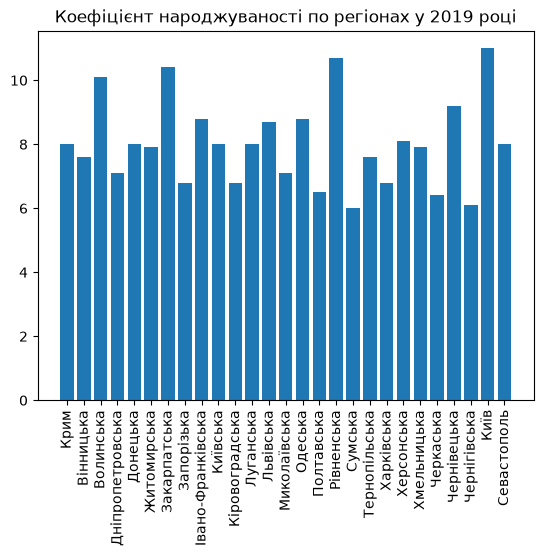

In [69]:
plt.bar(df["Регіон"],df["2019"])
plt.xticks(rotation=90)
plt.title("Коефіцієнт народжуваності по регіонах у 2019 році")
plt.show()


## Візуалізація

In [70]:
print(df)

               Регіон    1950       1960  1970  1990  2000  2012    2014  \
0                Крим  23.000  20.600000  16.0  13.0   7.3  12.6  11.144   
1           Вінницька  22.400  19.200000  14.2  12.4   8.4  11.2  10.900   
2           Волинська  24.700  25.000000  17.9  15.3  11.2  14.8  14.100   
3    Дніпропетровська  20.400  20.400000  15.1  12.3   7.1  11.2  11.100   
4            Донецька  27.100  21.400000  14.0  10.9   6.1   9.8   8.200   
5         Житомирська  26.100  22.300000  15.9  12.9   8.9  12.2  12.000   
6        Закарпатська  31.400  27.300000  20.7  16.8  11.5  15.1  14.600   
7          Запорізька  21.900  19.700000  15.0  12.4   7.1  10.6  10.600   
8   Івано-Франківська  24.300  24.800000  18.2  15.5  10.3  12.4  12.200   
9            Київська  20.400  18.900000  15.6  12.3   7.3  12.2  12.100   
10     Кіровоградська  21.600  17.100000  14.5  12.6   7.9  11.0  10.800   
11          Луганська  26.200  23.500000  14.4  11.6   6.2   9.6   5.100   
12          

               Регіон    1950  1960  1970  1990  2000  2012  2014  2019
2           Волинська  24.700  25.0  17.9  15.3  11.2  14.8  14.1  10.1
6        Закарпатська  31.400  27.3  20.7  16.8  11.5  15.1  14.6  10.4
8   Івано-Франківська  24.300  24.8  18.2  15.5  10.3  12.4  12.2   8.8
12          Львівська  23.400  24.0  17.1  14.0   9.1  11.9  11.9   8.7
14            Одеська  24.100  19.2  14.8  12.6   8.0  12.7  12.3   8.8
16         Рівненська  26.900  26.7  19.3  15.8  11.8  15.9  14.8  10.7
20         Херсонська  20.800  21.4  16.6  14.3   8.5  11.7  11.5   8.1
23        Чернівецька  24.700  21.8  17.0  14.8  10.1  12.8  12.9   9.2
25               Київ  23.104  17.4  15.9  12.0   7.3  12.0  12.1  11.0


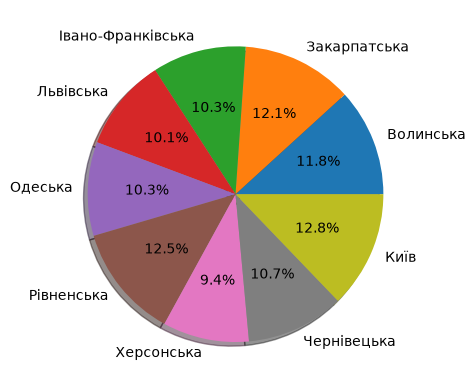

In [71]:
average=df["2019"].sum() / len(df)
rg=df[df["2019"]>average]
print(rg)
plt.pie(rg["2019"], labels=rg["Регіон"], autopct="%.1f%%", shadow=True)
plt.show()

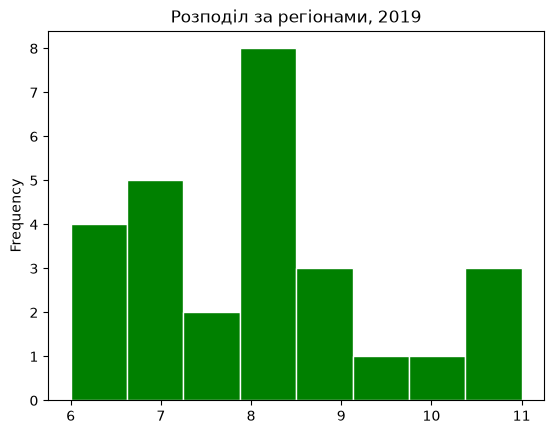

In [72]:
df["2019"].plot(kind="hist", bins=8, color="green", edgecolor="white")
plt.title("Розподіл за регіонами, 2019")
plt.show()

   1950  1960  1970  1990  2000  2012  2014  2019
1  22.4  19.2  14.2  12.4   8.4  11.2  10.9   7.6


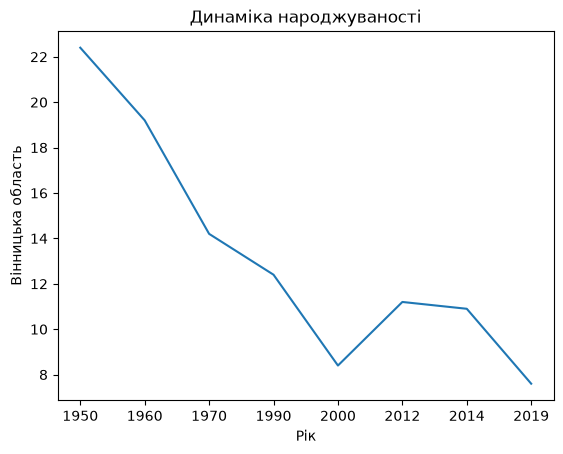

In [73]:
rg1=df[df["Регіон"]=="Вінницька"].drop(columns="Регіон")
print(rg1)
plt.plot(rg1.columns, rg1.values[0])
plt.xlabel("Рік")
plt.ylabel("Вінницька область")
plt.title("Динаміка народжуваності")
plt.show()